<a href="https://colab.research.google.com/github/KarunaBaruwal/CMP7005-Hypertension-Analytics/blob/main/CMP7005_Hypertension_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#from google.colab import drive

#drive.mount('/content/drive')

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
username = "Karuna Baruwal"
repo = "CMP7005-Hypertension-Analytics"

!git clone https://github.com/KarunaBaruwal/CMP7005-Hypertension-Analytics.git
%cd CMP7005-Hypertension-Analytics
%ls

Cloning into 'CMP7005-Hypertension-Analytics'...
remote: Enumerating objects: 27, done.
remote: Counting objects: 100% (27/27), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 27 (delta 13), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (27/27), 147.83 KiB | 1.97 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/CMP7005-Hypertension-Analytics
CMP7005_Hypertension_Analysis.ipynb  hypertension_dataset_5000.csv  README.md


In [5]:
file_path = "hypertension_dataset_5000.csv"
df = pd.read_csv(file_path)

In [6]:
df.head()

,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension
0,83.2,Male,24.6,92.5,Normal,Light,NaN,Former,Moderate,7.5,No,0.98,89.0,201.4,119,65,Normal,No
1,69.0,Female,26.1,76.6,Very High,Light,NaN,Former,Low,6.5,Yes,NaN,83.2,178.9,132,81,Stage 1 Hypertension,Yes
2,45.1,Male,24.5,86.4,High,Sedentary,Occasional,Former,Very High,6.1,No,1.02,86.0,163.2,131,87,Stage 1 Hypertension,Yes
3,45.5,Male,25.6,85.2,Normal,Active,Moderate,Current,High,6.4,Yes,0.86,80.5,146.0,127,88,Stage 1 Hypertension,Yes
4,41.7,Male,28.7,97.4,High,Active,Moderate,Current,High,6.9,No,1.27,97.0,210.6,120,78,Elevated,No


In [7]:
print("Number of patients:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of patients: 5000
Number of columns: 18


In [8]:
# Display column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     5000 non-null   float64
 1   Gender                  5000 non-null   object 
 2   BMI                     5000 non-null   float64
 3   Waist_Circumference_cm  4846 non-null   float64
 4   Salt_Intake             4939 non-null   object 
 5   Physical_Activity       5000 non-null   object 
 6   Alcohol_Consumption     3632 non-null   object 
 7   Smoking_Status          5000 non-null   object 
 8   Stress_Level            4909 non-null   object 
 9   Sleep_Hours             4837 non-null   float64
 10  Family_History_HTN      5000 non-null   object 
 11  Creatinine_mg_dL        4867 non-null   float64
 12  Fasting_Glucose_mg_dL   4821 non-null   float64
 13  Cholesterol_mg_dL       4841 non-null   float64
 14  Systolic_BP_mmHg        5000 non-null   

In [9]:
df.describe()

,Age,BMI,Waist_Circumference_cm,Sleep_Hours,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg
count,5000.000000,5000.000000,4846.000000,4837.000000,4867.000000,4821.000000,4841.000000,5000.000000,5000.000000
mean,48.648320,27.876320,89.417623,6.850444,0.942063,93.301058,187.219851,116.826600,74.259600
std,16.908037,4.254628,11.410790,1.042016,0.171618,12.753358,30.546704,16.385269,9.483849
min,18.200000,16.200000,54.000000,3.500000,0.510000,62.100000,105.000000,88.000000,50.000000
25%,34.575000,24.900000,81.500000,6.200000,0.820000,84.500000,165.600000,104.000000,67.000000
50%,47.400000,27.700000,89.100000,6.900000,0.930000,92.200000,187.300000,115.000000,74.000000
75%,61.600000,30.800000,97.100000,7.500000,1.050000,100.900000,207.600000,128.000000,81.000000
max,89.200000,43.500000,126.400000,10.500000,1.680000,173.400000,288.300000,181.000000,110.000000


In [10]:
# Count missing values in each column
display(df.isnull().sum())

# Count exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())

,0
Age,0
Gender,0
BMI,0
Waist_Circumference_cm,154
Salt_Intake,61
Physical_Activity,0
Alcohol_Consumption,1368
Smoking_Status,0
Stress_Level,91
Sleep_Hours,163


Duplicate rows: 0


Missing values Analysis

In [11]:
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': df.isnull().mean() * 100
})

missing_summary = missing_summary[
    missing_summary['Missing Count'] > 0
]

missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_summary.round(2))


,Missing Count,Missing Percentage
Alcohol_Consumption,1368,27.36
Fasting_Glucose_mg_dL,179,3.58
Sleep_Hours,163,3.26
Cholesterol_mg_dL,159,3.18
Waist_Circumference_cm,154,3.08
Creatinine_mg_dL,133,2.66
Stress_Level,91,1.82
Salt_Intake,61,1.22


In [12]:
df['Alcohol_Missing'] = df['Alcohol_Consumption'].isnull()
missing_by_htn = pd.crosstab(
    df['Hypertension'],
    df['Alcohol_Missing'],
    normalize='index'
) * 100
display(missing_by_htn.round(2))

Alcohol_Missing,False,True
Hypertension,,
No,70.25,29.75
Yes,77.09,22.91


In [13]:

pd.crosstab(
    df['Hypertension'],
    df['Alcohol_Consumption'].isna(),
    margins=True
)


Alcohol_Consumption,False,True,All
Hypertension,,,
No,2283,967,3250
Yes,1349,401,1750
All,3632,1368,5000


In [14]:
df = df.drop(columns=['Alcohol_Missing'])

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5000.0,48.648320,16.908037,18.20,34.575,47.40,61.60,89.20
BMI,5000.0,27.876320,4.254628,16.20,24.900,27.70,30.80,43.50
Waist_Circumference_cm,4846.0,89.417623,11.410790,54.00,81.500,89.10,97.10,126.40
Sleep_Hours,4837.0,6.850444,1.042016,3.50,6.200,6.90,7.50,10.50
Creatinine_mg_dL,4867.0,0.942063,0.171618,0.51,0.820,0.93,1.05,1.68
Fasting_Glucose_mg_dL,4821.0,93.301058,12.753358,62.10,84.500,92.20,100.90,173.40
Cholesterol_mg_dL,4841.0,187.219851,30.546704,105.00,165.600,187.30,207.60,288.30
Systolic_BP_mmHg,5000.0,116.826600,16.385269,88.00,104.000,115.00,128.00,181.00
Diastolic_BP_mmHg,5000.0,74.259600,9.483849,50.00,67.000,74.00,81.00,110.00


In [16]:
numeric_summary = df.describe().T

display(
    numeric_summary[['count', 'mean', 'min', 'max']]
    .round(2)
)

,count,mean,min,max
Age,5000.0,48.65,18.20,89.20
BMI,5000.0,27.88,16.20,43.50
Waist_Circumference_cm,4846.0,89.42,54.00,126.40
Sleep_Hours,4837.0,6.85,3.50,10.50
Creatinine_mg_dL,4867.0,0.94,0.51,1.68
Fasting_Glucose_mg_dL,4821.0,93.30,62.10,173.40
Cholesterol_mg_dL,4841.0,187.22,105.00,288.30
Systolic_BP_mmHg,5000.0,116.83,88.00,181.00
Diastolic_BP_mmHg,5000.0,74.26,50.00,110.00


In [17]:
invalid_bp = (
    df['Systolic_BP_mmHg'] <= df['Diastolic_BP_mmHg']
).sum()

print("Records requiring BP consistency review:", invalid_bp)

Records requiring BP consistency review: 0


In [18]:
categorical_cols = df.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_cols:
    print(f"\nColumn: {col}")
    display(df[col].value_counts(dropna=False))


Column: Gender


,count
Gender,
Female,2581
Male,2419



Column: Salt_Intake


,count
Salt_Intake,
Normal,1696
High,1597
Very High,1011
Low,635
NaN,61



Column: Physical_Activity


,count
Physical_Activity,
Light,1678
Sedentary,1327
Moderate,1258
Active,737


... (8 outputs left out)


Column: BP_Category


,count
BP_Category,
Normal,2713
Stage 1 Hypertension,1147
Stage 2 Hypertension,603
Elevated,537



Column: Hypertension


,count
Hypertension,
No,3250
Yes,1750


In [19]:
categorical_summary = []

for col in categorical_cols:
    categories = df[col].dropna().unique()
    categorical_summary.append({
        'Variable': col,
        'Unique Categories': len(categories),
        'Category Names': ', '.join(map(str, categories)),
        'Missing Values': df[col].isna().sum()
    })
display(pd.DataFrame(categorical_summary))

,Variable,Unique Categories,Category Names,Missing Values
0,Gender,2,"Male, Female",0
1,Salt_Intake,4,"Normal, Very High, High, Low",61
2,Physical_Activity,4,"Light, Sedentary, Active, Moderate",0
3,Alcohol_Consumption,3,"Occasional, Moderate, Heavy",1368
4,Smoking_Status,3,"Former, Current, Never",0
5,Stress_Level,4,"Moderate, Low, Very High, High",91
6,Family_History_HTN,2,"No, Yes",0
7,BP_Category,4,"Normal, Stage 1 Hypertension, Elevated, Stage ...",0
8,Hypertension,2,"No, Yes",0


In [20]:
bp_relationship = pd.crosstab(
    df['BP_Category'],
    df['Hypertension']
)

display(bp_relationship)


Hypertension,No,Yes
BP_Category,,
Elevated,537,0
Normal,2713,0
Stage 1 Hypertension,0,1147
Stage 2 Hypertension,0,603


In [21]:

df.groupby('BP_Category')[
    ['Systolic_BP_mmHg', 'Diastolic_BP_mmHg']
].agg(['min', 'max', 'mean']).round(2)


Systolic_BP_mmHg              Diastolic_BP_mmHg       \
                                  min  max    mean               min  max   
BP_Category                                                                 
Elevated                          120  129  124.03                55   79   
Normal                             88  119  104.93                50   79   
Stage 1 Hypertension              105  139  126.60                59   89   
Stage 2 Hypertension              116  181  145.34                66  110   

                             
                       mean  
BP_Category                  
Elevated              73.92  
Normal                68.05  
Stage 1 Hypertension  81.76  
Stage 2 Hypertension  88.22

In [22]:

df.loc[
    (df['BP_Category'] == 'Stage 1 Hypertension') &
    (df['Systolic_BP_mmHg'] < 120),
    ['Systolic_BP_mmHg', 'Diastolic_BP_mmHg', 'BP_Category']
].head(10)


,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category
41,113,81,Stage 1 Hypertension
61,115,80,Stage 1 Hypertension
65,119,80,Stage 1 Hypertension
83,112,84,Stage 1 Hypertension
125,117,84,Stage 1 Hypertension
134,109,82,Stage 1 Hypertension
148,111,81,Stage 1 Hypertension
167,114,82,Stage 1 Hypertension
197,107,82,Stage 1 Hypertension
206,118,80,Stage 1 Hypertension


Initial finding of stress level of question 1

In [23]:
df['Stress_Level'].value_counts(dropna=False)

,count
Stress_Level,
Moderate,1844
High,1410
Low,844
Very High,811
NaN,91


In [24]:
df['Family_History_HTN'].value_counts(dropna=False)


,count
Family_History_HTN,
No,3218
Yes,1782


In [25]:
df['Physical_Activity'].value_counts(dropna=False)

,count
Physical_Activity,
Light,1678
Sedentary,1327
Moderate,1258
Active,737


In [26]:
df['Smoking_Status'].value_counts(dropna=False)

,count
Smoking_Status,
Never,2805
Former,1440
Current,755


In [27]:
df['Gender'].value_counts(dropna=False)

,count
Gender,
Female,2581
Male,2419


In [28]:
df['Salt_Intake'].value_counts(dropna=False)

,count
Salt_Intake,
Normal,1696
High,1597
Very High,1011
Low,635
NaN,61


In [29]:
df['Alcohol_Consumption'].value_counts(dropna=False)

,count
Alcohol_Consumption,
Occasional,1910
NaN,1368
Moderate,1231
Heavy,491


In [30]:
df['BP_Category'].value_counts(dropna=False)

,count
BP_Category,
Normal,2713
Stage 1 Hypertension,1147
Stage 2 Hypertension,603
Elevated,537


In [31]:
df['Hypertension'].value_counts(dropna=False)

,count
Hypertension,
No,3250
Yes,1750


In [32]:
pd.crosstab(
    df['BP_Category'],
    df['Hypertension']
)

Hypertension,No,Yes
BP_Category,,
Elevated,537,0
Normal,2713,0
Stage 1 Hypertension,0,1147
Stage 2 Hypertension,0,603


2713 are classified as normal and 537 are classified as elevated meaning not having hypertension


In [33]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5000.0,48.648320,16.908037,18.20,34.575,47.40,61.60,89.20
BMI,5000.0,27.876320,4.254628,16.20,24.900,27.70,30.80,43.50
Waist_Circumference_cm,4846.0,89.417623,11.410790,54.00,81.500,89.10,97.10,126.40
Sleep_Hours,4837.0,6.850444,1.042016,3.50,6.200,6.90,7.50,10.50
Creatinine_mg_dL,4867.0,0.942063,0.171618,0.51,0.820,0.93,1.05,1.68
Fasting_Glucose_mg_dL,4821.0,93.301058,12.753358,62.10,84.500,92.20,100.90,173.40
Cholesterol_mg_dL,4841.0,187.219851,30.546704,105.00,165.600,187.30,207.60,288.30
Systolic_BP_mmHg,5000.0,116.826600,16.385269,88.00,104.000,115.00,128.00,181.00
Diastolic_BP_mmHg,5000.0,74.259600,9.483849,50.00,67.000,74.00,81.00,110.00


In [34]:
df.describe().T[['count', 'mean', 'min', 'max']].round(2)

,count,mean,min,max
Age,5000.0,48.65,18.20,89.20
BMI,5000.0,27.88,16.20,43.50
Waist_Circumference_cm,4846.0,89.42,54.00,126.40
Sleep_Hours,4837.0,6.85,3.50,10.50
Creatinine_mg_dL,4867.0,0.94,0.51,1.68
Fasting_Glucose_mg_dL,4821.0,93.30,62.10,173.40
Cholesterol_mg_dL,4841.0,187.22,105.00,288.30
Systolic_BP_mmHg,5000.0,116.83,88.00,181.00
Diastolic_BP_mmHg,5000.0,74.26,50.00,110.00


In [35]:
Q1 = df['BMI'].quantile(0.25)
Q3 = df['BMI'].quantile(0.75)
IQR = Q3 - Q1
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)


Lower limit: 16.049999999999997
Upper limit: 39.650000000000006


In [36]:

bmi_outliers = df[
    (df['BMI'] < lower_limit) |
    (df['BMI'] > upper_limit)
]

print("Number of possible BMI outliers:", len(bmi_outliers))


Number of possible BMI outliers: 23


In [37]:
bmi_outliers[['Age', 'BMI', 'Hypertension']].head(10)

,Age,BMI,Hypertension
165,52.4,41.6,Yes
369,74.2,41.4,Yes
558,42.7,40.3,No
574,76.2,41.7,Yes
762,68.3,40.7,Yes
1228,70.5,41.4,No
2527,62.8,40.1,No
2560,83.5,41.7,Yes
2598,78.9,39.9,Yes
2649,48.3,40.1,Yes


In [38]:
df[
    df['Systolic_BP_mmHg'] <= df['Diastolic_BP_mmHg']
]

,Age,Gender,BMI,Waist_Circumference_cm,Salt_Intake,Physical_Activity,Alcohol_Consumption,Smoking_Status,Stress_Level,Sleep_Hours,Family_History_HTN,Creatinine_mg_dL,Fasting_Glucose_mg_dL,Cholesterol_mg_dL,Systolic_BP_mmHg,Diastolic_BP_mmHg,BP_Category,Hypertension


In [39]:
invalid_bp = df[
    df['Systolic_BP_mmHg'] <= df['Diastolic_BP_mmHg']
]

len(invalid_bp)

0

Task 2b

In [40]:
df_clean = df.copy()

In [41]:
df_clean.shape


(5000, 18)

In [42]:
df_clean['Alcohol_Consumption'] = df_clean['Alcohol_Consumption'].fillna('Unknown')

In [43]:
df_clean['Alcohol_Consumption'].value_counts(dropna=False)

,count
Alcohol_Consumption,
Occasional,1910
Unknown,1368
Moderate,1231
Heavy,491


In [44]:
df_clean['Stress_Level'] = df_clean['Stress_Level'].fillna('Unknown')
df_clean['Salt_Intake'] = df_clean['Salt_Intake'].fillna('Unknown')

In [45]:
df_clean['Stress_Level'].value_counts(dropna=False)

,count
Stress_Level,
Moderate,1844
High,1410
Low,844
Very High,811
Unknown,91


In [46]:
df_clean['Salt_Intake'].value_counts(dropna=False)

,count
Salt_Intake,
Normal,1696
High,1597
Very High,1011
Low,635
Unknown,61


In [47]:
df_clean[[
    'Fasting_Glucose_mg_dL',
    'Sleep_Hours',
    'Cholesterol_mg_dL',
    'Waist_Circumference_cm',
    'Creatinine_mg_dL'
]].median()

,0
Fasting_Glucose_mg_dL,92.20
Sleep_Hours,6.90
Cholesterol_mg_dL,187.30
Waist_Circumference_cm,89.10
Creatinine_mg_dL,0.93


In [48]:
df_clean['Sleep_Hours'] = df_clean['Sleep_Hours'].fillna(
    df_clean['Sleep_Hours'].median()
)

In [49]:
df_clean['Sleep_Hours'].isnull().sum()

np.int64(0)

In [50]:
df_clean['Fasting_Glucose_mg_dL'] = df_clean['Fasting_Glucose_mg_dL'].fillna(df_clean['Fasting_Glucose_mg_dL'].median())

df_clean['Cholesterol_mg_dL'] = df_clean['Cholesterol_mg_dL'].fillna(df_clean['Cholesterol_mg_dL'].median())

df_clean['Waist_Circumference_cm'] = df_clean['Waist_Circumference_cm'].fillna(df_clean['Waist_Circumference_cm'].median())

df_clean['Creatinine_mg_dL'] = df_clean['Creatinine_mg_dL'].fillna(df_clean['Creatinine_mg_dL'].median())

In [51]:
df_clean.isnull().sum()

,0
Age,0
Gender,0
BMI,0
Waist_Circumference_cm,0
Salt_Intake,0
Physical_Activity,0
Alcohol_Consumption,0
Smoking_Status,0
Stress_Level,0
Sleep_Hours,0


In [52]:
df_clean.shape

(5000, 18)

In [53]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (5000, 18)
Cleaned dataset: (5000, 18)


In [54]:
df_clean.duplicated().sum()

np.int64(0)

In [55]:
df_clean['HTN_Flag'] = df_clean['Hypertension'].map({
    'No': 0,
    'Yes': 1
})

In [56]:
df_clean.duplicated().sum()
df_clean['HTN_Flag'].value_counts(dropna=False)

,count
HTN_Flag,
0,3250
1,1750


In [57]:
df_clean['Age_Group'] = pd.cut(
    df_clean['Age'],
    bins=[0, 40, 60, 120],
    labels=['18-39', '40-59', '60+'],
    right=False
)

In [58]:
df_clean[['Age', 'Age_Group']].head(10)

,Age,Age_Group
0,83.2,60+
1,69.0,60+
2,45.1,40-59
3,45.5,40-59
4,41.7,40-59
5,31.5,18-39
6,56.6,40-59
7,60.1,60+
8,55.0,40-59
9,30.7,18-39


In [59]:
df_clean['Age_Group'].value_counts(dropna=False)

,count
Age_Group,
40-59,1841
18-39,1766
60+,1393


In [60]:
df_clean['Pulse_Pressure'] = (
    df_clean['Systolic_BP_mmHg'] -
    df_clean['Diastolic_BP_mmHg']
)

In [61]:
df_clean[[
    'Systolic_BP_mmHg',
    'Diastolic_BP_mmHg',
    'Pulse_Pressure'
]].head(10)

,Systolic_BP_mmHg,Diastolic_BP_mmHg,Pulse_Pressure
0,119,65,54
1,132,81,51
2,131,87,44
3,127,88,39
4,120,78,42
5,112,78,34
6,113,71,42
7,126,91,35
8,131,89,42
9,99,69,30


# Feature Engineering and Encoding

In [62]:
df_clean[['HTN_Flag', 'Age_Group', 'Pulse_Pressure']].isnull().sum()

,0
HTN_Flag,0
Age_Group,0
Pulse_Pressure,0


In [63]:
df_clean['HTN_Flag'].mean() * 100

np.float64(35.0)

In [64]:
df_clean.groupby('Stress_Level')['HTN_Flag'].mean() * 100

,HTN_Flag
Stress_Level,
High,36.524823
Low,30.331754
Moderate,31.507592
Unknown,42.857143
Very High,44.266338


In [65]:
stress_rates = df_clean.groupby('Stress_Level')['HTN_Flag'].mean() * 100

stress_rates = stress_rates.reindex([
    'Low',
    'Moderate',
    'High',
    'Very High'
])

stress_rates.round(2)


,HTN_Flag
Stress_Level,
Low,30.33
Moderate,31.51
High,36.52
Very High,44.27


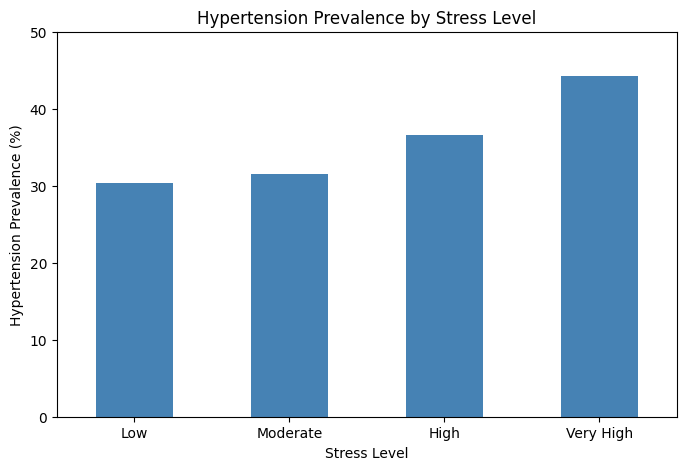

In [66]:

stress_rates.plot(
    kind='bar',
    figsize=(8, 5),
    color='steelblue'
)

plt.title('Hypertension Prevalence by Stress Level')
plt.xlabel('Stress Level')
plt.ylabel('Hypertension Prevalence (%)')
plt.xticks(rotation=0)
plt.ylim(0, 50)
plt.show()


In [67]:

stress_summary = df_clean.groupby('Stress_Level')['HTN_Flag'].agg(
    ['count', 'sum', 'mean']
)

stress_summary['mean'] = (stress_summary['mean'] * 100).round(2)

stress_summary


,count,sum,mean
Stress_Level,,,
High,1410,515,36.52
Low,844,256,30.33
Moderate,1844,581,31.51
Unknown,91,39,42.86
Very High,811,359,44.27
